<a href="https://colab.research.google.com/github/catherin-punnya/Portfolio/blob/main/os_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


ACTIVITY 1: WITHOUT CONTEXT SWITCHING OVERHEAD

Time Quantum = 2 ms

Gantt chart intervals:
P1(0-2) -> P2(2-4) -> P3(4-6) -> P1(6-8) -> P4(8-10) -> P2(10-11) -> P3(11-13) -> P1(13-14)


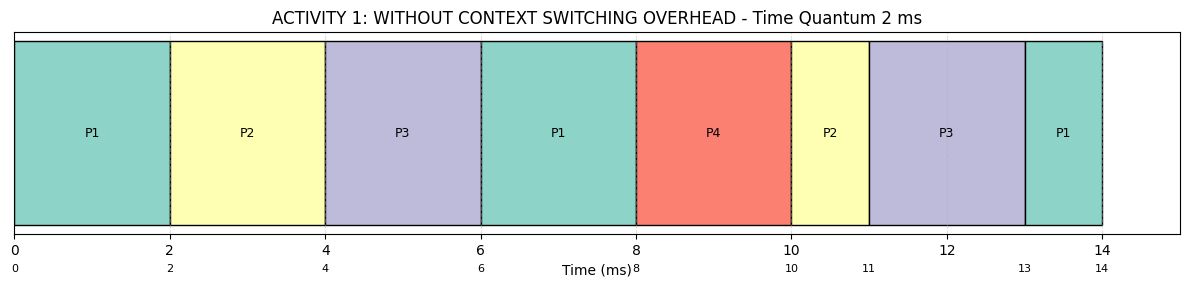


Process performance table:
Process  AT  BT  CT  TAT  WT  RT
     P1   0   5  14   14   9   0
     P2   1   3  11   10   7   1
     P3   2   4  13   11   7   2
     P4   3   2  10    7   5   5

Performance summary:
Average TAT: 10.50
Average WT: 7.00
Average RT: 2.00
Context switches: 7.00
Total overhead: 0.00
CPU efficiency (%): 100.00

Time Quantum = 3 ms

Gantt chart intervals:
P1(0-3) -> P2(3-6) -> P3(6-9) -> P4(9-11) -> P1(11-13) -> P3(13-14)


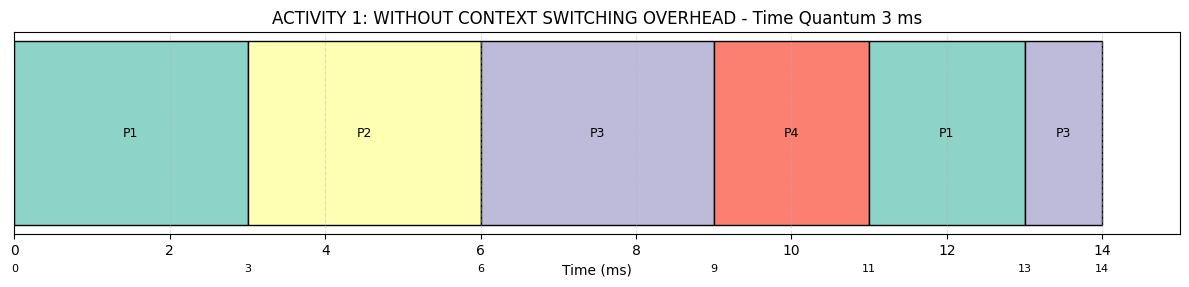


Process performance table:
Process  AT  BT  CT  TAT  WT  RT
     P1   0   5  13   13   8   0
     P2   1   3   6    5   2   2
     P3   2   4  14   12   8   4
     P4   3   2  11    8   6   6

Performance summary:
Average TAT: 9.50
Average WT: 6.00
Average RT: 3.00
Context switches: 5.00
Total overhead: 0.00
CPU efficiency (%): 100.00

Comparison table:
 Time Quantum  Average TAT  Average WT  Average RT  Context switches  Total overhead  CPU efficiency (%)
            2         10.5         7.0         2.0                 7               0               100.0
            3          9.5         6.0         3.0                 5               0               100.0

ACTIVITY 2: WITH CONTEXT SWITCHING OVERHEAD

Time Quantum = 2 ms

Gantt chart intervals:
P1(0-2) -> CS(2-3) -> P2(3-5) -> CS(5-6) -> P3(6-8) -> CS(8-9) -> P1(9-11) -> CS(11-12) -> P4(12-14) -> CS(14-15) -> P2(15-17) -> CS(17-18) -> P3(18-19) -> CS(19-20) -> P1(20-21)


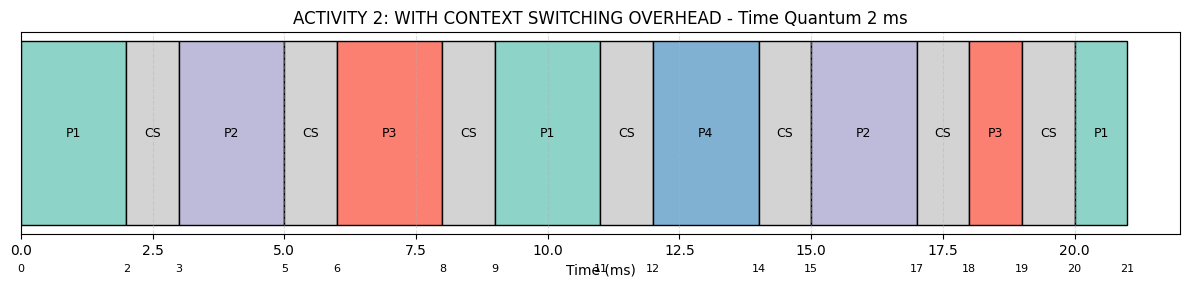


Process performance table:
Process  AT  BT  CT  TAT  WT  RT
     P1   0   5  21   21  16   0
     P2   1   4  17   16  12   2
     P3   2   3  19   17  14   4
     P4   3   2  14   11   9   9

Performance summary:
Average TAT: 16.25
Average WT: 12.75
Average RT: 3.75
Context switches: 7.00
Total overhead: 7.00
CPU efficiency (%): 66.67

Time Quantum = 4 ms

Gantt chart intervals:
P1(0-4) -> CS(4-5) -> P2(5-9) -> CS(9-10) -> P3(10-13) -> CS(13-14) -> P4(14-16) -> CS(16-17) -> P1(17-18)


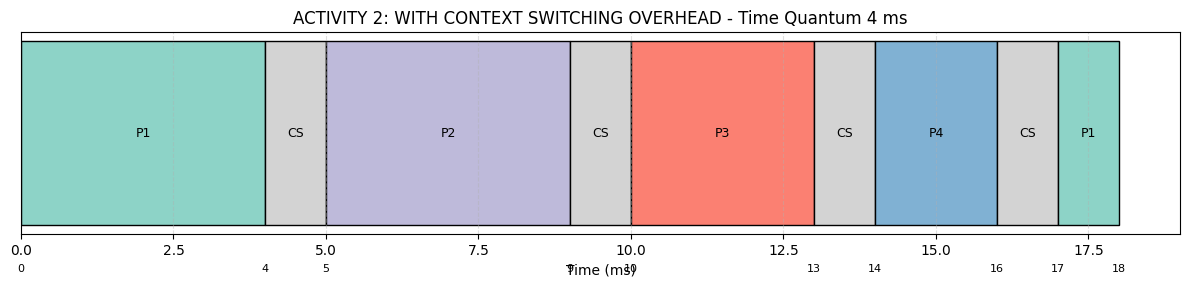


Process performance table:
Process  AT  BT  CT  TAT  WT  RT
     P1   0   5  18   18  13   0
     P2   1   4   9    8   4   4
     P3   2   3  13   11   8   8
     P4   3   2  16   13  11  11

Performance summary:
Average TAT: 12.50
Average WT: 9.00
Average RT: 5.75
Context switches: 4.00
Total overhead: 4.00
CPU efficiency (%): 77.78

Comparison table:
 Time Quantum  Average TAT  Average WT  Average RT  Context switches  Total overhead  CPU efficiency (%)
            2        16.25       12.75        3.75                 7               7               66.67
            4        12.50        9.00        5.75                 4               4               77.78


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from collections import deque


def round_robin(processes, quantum, overhead=0):
    remaining = {p: burst for p, arrival, burst in processes}
    arrival = {p: arr for p, arr, burst in processes}
    burst = {p: b for p, arr, b in processes}

    first_start = {}
    completion = {}
    gantt = []
    ready = deque()
    added = set()
    time = 0
    last_process = None
    switches = 0

    def add_arrivals(now):
        for p, arr, b in processes:
            if arr <= now and p not in added:
                ready.append(p)
                added.add(p)

    while len(completion) < len(processes):
        add_arrivals(time)

        if not ready:
            future = [
                arr for p, arr, b in processes
                if p not in added
            ]
            if future:
                next_time = min(future)
                if next_time > time:
                    gantt.append(
                        ("Idle", time, next_time)
                    )
                    time = next_time
                last_process = None
                add_arrivals(time)
            continue

        p = ready.popleft()


        if last_process is not None and last_process != p:
            switches += 1

            if overhead > 0:
                gantt.append(
                    ("CS", time, time + overhead)
                )
                time += overhead
                add_arrivals(time)


        if p not in first_start:
            first_start[p] = time

        run_time = min(quantum, remaining[p])
        start = time
        time += run_time
        remaining[p] -= run_time
        gantt.append((p, start, time))


        add_arrivals(time)

        if remaining[p] == 0:
            completion[p] = time
        else:
            ready.append(p)

        last_process = p

    rows = []
    for p, arr, b in processes:
        ct = completion[p]
        tat = ct - arr
        wt = tat - b
        rt = first_start[p] - arr

        rows.append({
            "Process": p,
            "AT": arr,
            "BT": b,
            "CT": ct,
            "TAT": tat,
            "WT": wt,
            "RT": rt
        })

    df = pd.DataFrame(rows)
    total_time = max(end for label, start, end in gantt)
    total_burst = sum(b for p, arr, b in processes)
    total_overhead = switches * overhead

    summary = {
        "Average TAT": df["TAT"].mean(),
        "Average WT": df["WT"].mean(),
        "Average RT": df["RT"].mean(),
        "Context switches": switches,
        "Total overhead": total_overhead,
        "CPU efficiency (%)":
            total_burst / total_time * 100
            if total_time else 0
    }

    return df, gantt, summary


def show_gantt(gantt, title):
    fig, ax = plt.subplots(figsize=(12, 3))

    labels = list(dict.fromkeys(
        label for label, start, end in gantt
    ))
    colors = {}
    palette = plt.cm.Set3.colors

    for i, label in enumerate(labels):
        colors[label] = (
            "lightgray" if label in ("CS", "Idle")
            else palette[i % len(palette)]
        )

    for label, start, end in gantt:
        ax.barh(
            0, end - start, left=start, height=0.5,
            color=colors[label], edgecolor="black"
        )
        ax.text(
            (start + end) / 2, 0, label,
            ha="center", va="center", fontsize=9
        )
        ax.text(start, -0.38, str(start),
                ha="center", fontsize=8)

    ax.text(gantt[-1][2], -0.38,
            str(gantt[-1][2]), ha="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("Time (ms)")
    ax.set_yticks([])
    ax.set_xlim(0, gantt[-1][2] + 1)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


def run_activity(title, processes, quantums, overhead=0):
    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    results = []

    for q in quantums:
        df, gantt, summary = round_robin(
            processes, q, overhead
        )

        print(f"\nTime Quantum = {q} ms")
        print("\nGantt chart intervals:")
        print(" -> ".join(
            f"{label}({start}-{end})"
            for label, start, end in gantt
        ))

        show_gantt(
            gantt,
            f"{title} - Time Quantum {q} ms"
        )

        print("\nProcess performance table:")
        print(df.to_string(index=False))

        print("\nPerformance summary:")
        for name, value in summary.items():
            print(f"{name}: {value:.2f}")

        results.append({
            "Time Quantum": q,
            **summary
        })

    comparison = pd.DataFrame(results)
    print("\nComparison table:")
    print(comparison.round(2).to_string(index=False))
    return comparison

activity1 = [
    ("P1", 0, 5),
    ("P2", 1, 3),
    ("P3", 2, 4),
    ("P4", 3, 2)
]

comparison1 = run_activity(
    "ACTIVITY 1: WITHOUT CONTEXT SWITCHING OVERHEAD",
    activity1,
    [2, 3],
    overhead=0
)

activity2 = [
    ("P1", 0, 5),
    ("P2", 1, 4),
    ("P3", 2, 3),
    ("P4", 3, 2)
]

comparison2 = run_activity(
    "ACTIVITY 2: WITH CONTEXT SWITCHING OVERHEAD",
    activity2,
    [2, 4],
    overhead=1
)
